In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/creditcard.csv")
print(df.shape)
print(df.isna().sum().sum(), "missing values")
print(df.duplicated().sum(), "Duplicate rows")
print(df["Class"].value_counts())
print(df["Class"].mean())
print("Time range (hours):", df["Time"].min() / 3600, "to", df["Time"].max() / 3600)
df.describe().T.head(10)

(284807, 31)
0 missing values
Class
0    284315
1       492
Name: count, dtype: int64
0.001727485630620034
Time range (hours): 0.0 to 47.99777777777778


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


<Axes: xlabel='Class'>

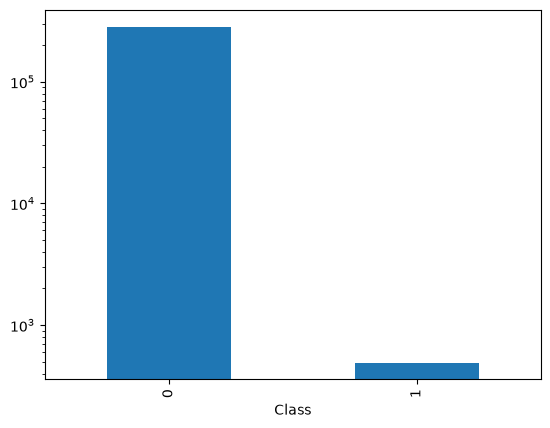

In [3]:
df["Class"].value_counts().plot(kind="bar", logy=True)

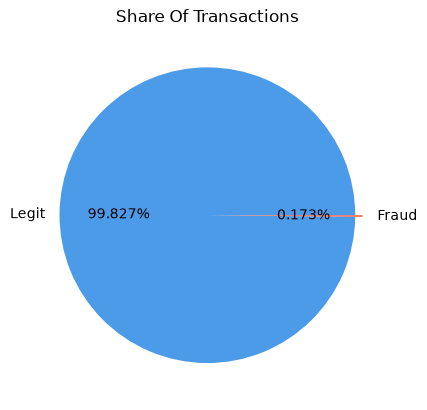

In [4]:
counts = df["Class"].value_counts().sort_index() 

plt.pie(counts, labels=["Legit", "Fraud"], autopct="%1.3f%%",
          explode=(0, 0.05), colors=["#4c9be8", "#e8604c"])
plt.title("Share Of Transactions")
plt.show()

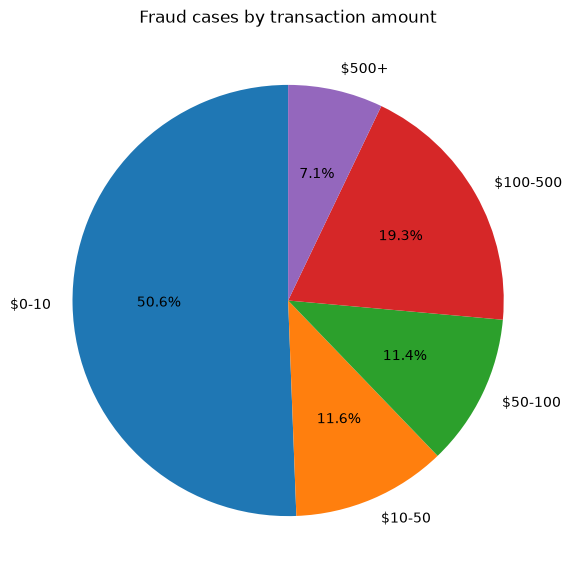

In [5]:
bins = [0, 10, 50, 100, 500, np.inf]
names = ["$0-10", "$10-50", "$50-100", "$100-500", "$500+"]
df["amt_bucket"] = pd.cut(df["Amount"], bins=bins, labels=names, include_lowest=True)

fraud_amt = df[df["Class"] == 1]["amt_bucket"].value_counts().reindex(names)

plt.figure(figsize=(7, 7))
plt.pie(fraud_amt, labels=fraud_amt.index, autopct="%1.1f%%", startangle=90)
plt.title("Fraud cases by transaction amount")
plt.show()

Time Vs Fraud Curve - Shows around what time max transactions were fraudulent (around 1-4 AM)

<Axes: xlabel='hour'>

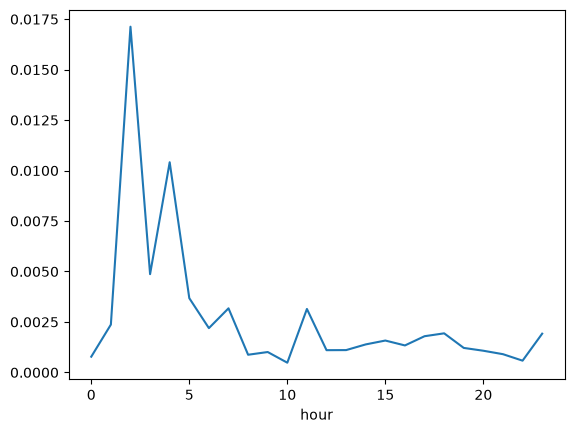

In [6]:
df["hour"] = (df["Time"] // 3600) % 24
df.groupby("hour")["Class"].mean().plot()

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87


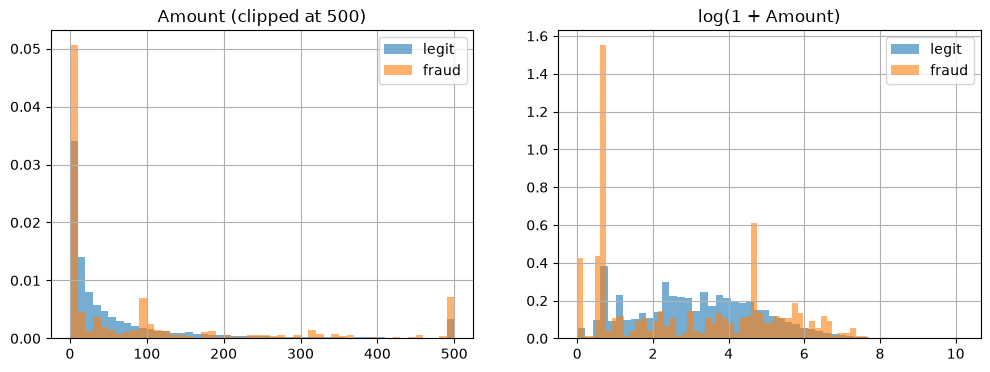

In [7]:
print(df.groupby("Class")["Amount"].describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df[df.Class == 0]["Amount"].clip(upper=500).hist(bins=50, alpha=.6, label="legit", ax=ax[0], density=True)
df[df.Class == 1]["Amount"].clip(upper=500).hist(bins=50, alpha=.6, label="fraud", ax=ax[0], density=True)
ax[0].set_title("Amount (clipped at 500)"); ax[0].legend()

np.log1p(df[df.Class == 0]["Amount"]).hist(bins=50, alpha=.6, label="legit", ax=ax[1], density=True)
np.log1p(df[df.Class == 1]["Amount"]).hist(bins=50, alpha=.6, label="fraud", ax=ax[1], density=True)
ax[1].set_title("log(1 + Amount)"); ax[1].legend()
plt.show()

,total_transactions,fraud_cases,fraud_rate_pct
amt_bucket,,,
$0–10,100264,249,0.2483
$10–50,90781,57,0.0628
$50–100,37254,56,0.1503
$100–500,47366,95,0.2006
$500+,9142,35,0.3828


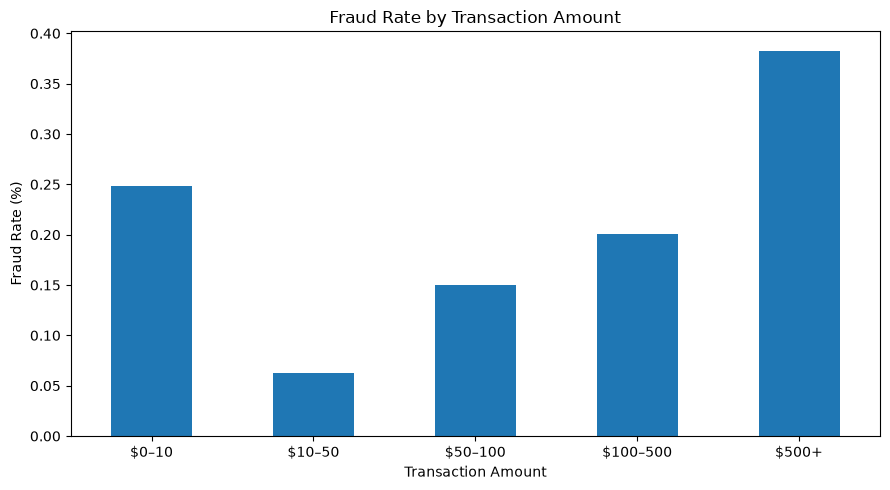

In [9]:

# Create transaction amount groups
bins = [0, 10, 50, 100, 500, np.inf]
labels = ["$0–10", "$10–50", "$50–100", "$100–500", "$500+"]

df["amt_bucket"] = pd.cut(
    df["Amount"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# Calculate total transactions and frauds in each group
amount_analysis = df.groupby(
    "amt_bucket", observed=False
).agg(
    total_transactions=("Class", "count"),
    fraud_cases=("Class", "sum")
)

# Fraud rate = fraud cases / total transactions
amount_analysis["fraud_rate_pct"] = (
    amount_analysis["fraud_cases"]
    / amount_analysis["total_transactions"] * 100
)

display(amount_analysis.round(4))

# Plot fraud rate
amount_analysis["fraud_rate_pct"].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Fraud Rate by Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


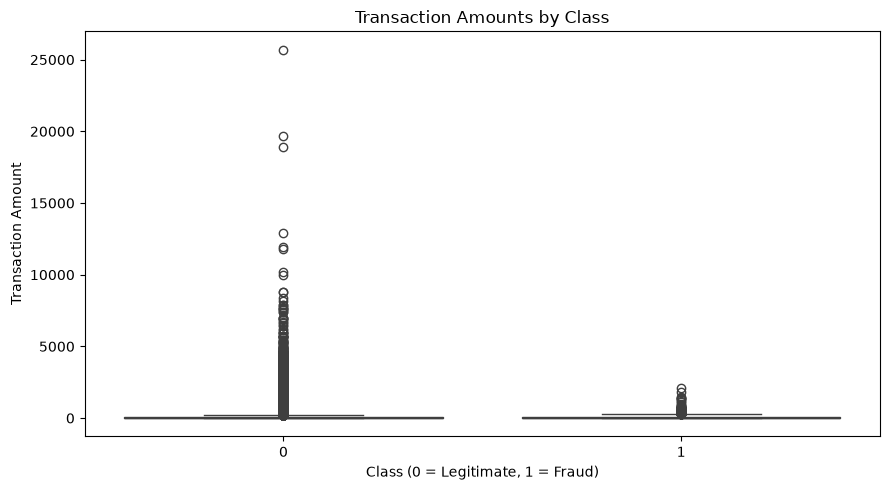

        count    mean  median  min       max
Class                                       
0      284315   88.29   22.00  0.0  25691.16
1         492  122.21    9.25  0.0   2125.87


In [10]:
import seaborn as sns
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amounts by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.tight_layout()
plt.show()

print(
    df.groupby("Class")["Amount"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)


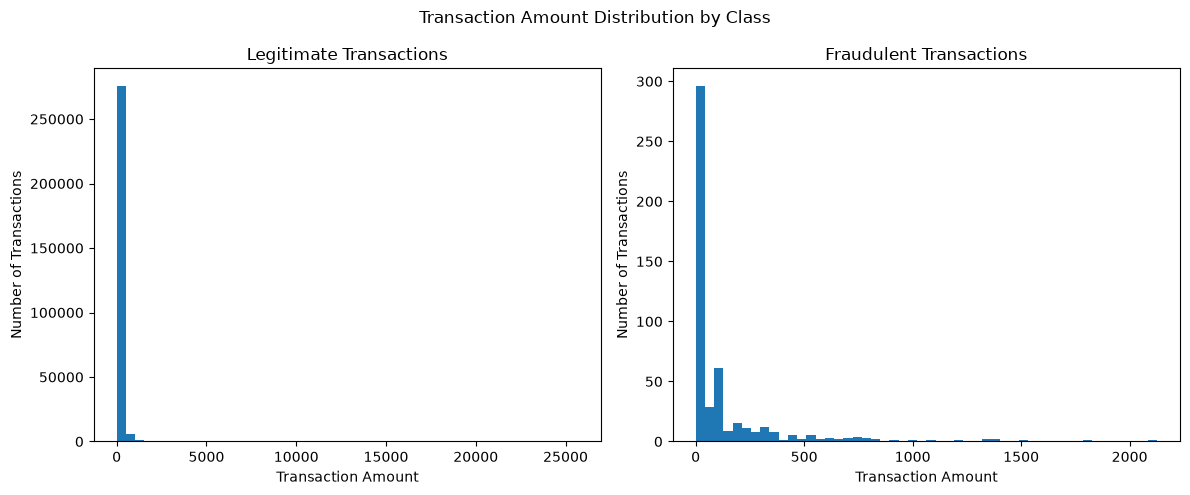

In [13]:

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Legitimate transactions
ax[0].hist(
    df[df["Class"] == 0]["Amount"],
    bins=50
)
ax[0].set_title("Legitimate Transactions")
ax[0].set_xlabel("Transaction Amount")
ax[0].set_ylabel("Number of Transactions")

# Fraudulent transactions
ax[1].hist(
    df[df["Class"] == 1]["Amount"],
    bins=50
)
ax[1].set_title("Fraudulent Transactions")
ax[1].set_xlabel("Transaction Amount")
ax[1].set_ylabel("Number of Transactions")

plt.suptitle("Transaction Amount Distribution by Class")
plt.tight_layout()
plt.show()


In [14]:

v_features = [
    col for col in df.columns
    if col.startswith("V") and col[1:].isdigit()
]

print("Number of V features:", len(v_features))
print("\nSummary of transformed features:")

display(df[v_features].describe().T.round(3))


Number of V features: 28

Summary of transformed features:


,count,mean,std,min,25%,50%,75%,max
V1,284807.0,0.0,1.959,-56.408,-0.920,0.018,1.316,2.455
V2,284807.0,0.0,1.651,-72.716,-0.599,0.065,0.804,22.058
V3,284807.0,-0.0,1.516,-48.326,-0.890,0.180,1.027,9.383
V4,284807.0,0.0,1.416,-5.683,-0.849,-0.020,0.743,16.875
V5,284807.0,0.0,1.380,-113.743,-0.692,-0.054,0.612,34.802
V6,284807.0,0.0,1.332,-26.161,-0.768,-0.274,0.399,73.302
V7,284807.0,-0.0,1.237,-43.557,-0.554,0.040,0.570,120.589
V8,284807.0,0.0,1.194,-73.217,-0.209,0.022,0.327,20.007
V9,284807.0,-0.0,1.099,-13.434,-0.643,-0.051,0.597,15.595
V10,284807.0,0.0,1.089,-24.588,-0.535,-0.093,0.454,23.745


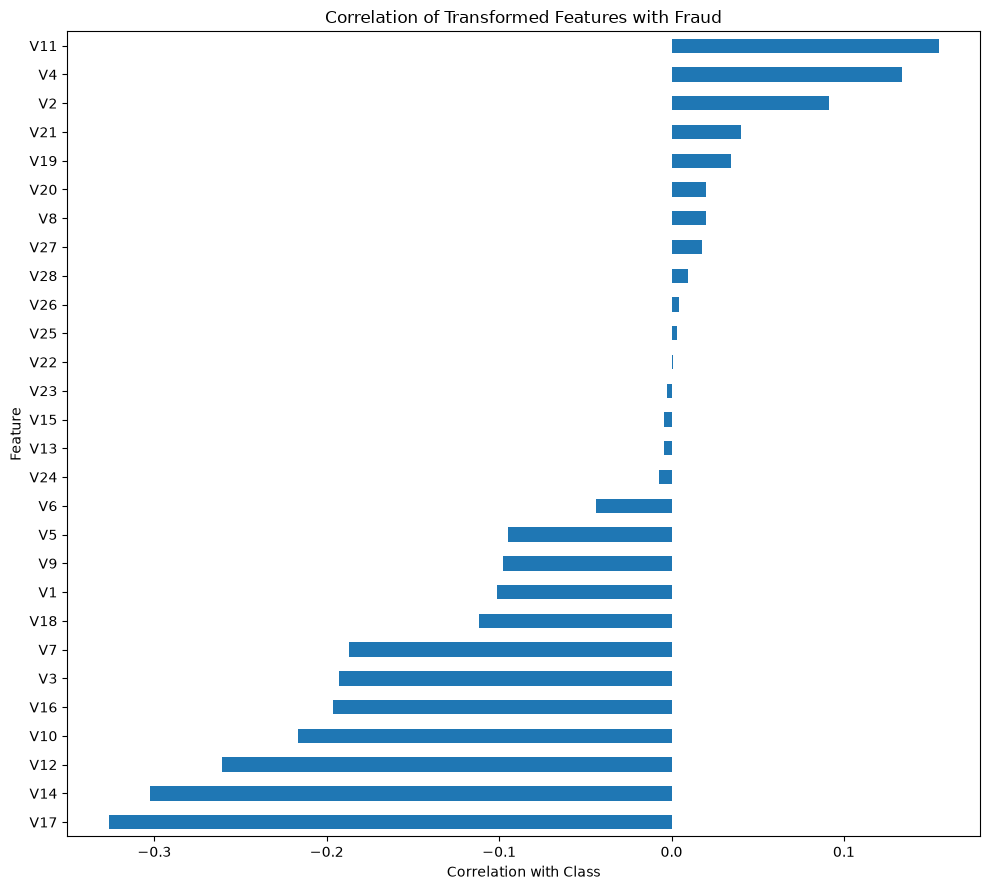

Most negatively correlated features:


V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
Name: Class, dtype: float64

Most positively correlated features:


V11    0.154876
V4     0.133447
V2     0.091289
V21    0.040413
V19    0.034783
Name: Class, dtype: float64

In [15]:

correlations = (
    df[v_features + ["Class"]]
    .corr()["Class"]
    .drop("Class")
    .sort_values()
)

plt.figure(figsize=(10, 9))

correlations.plot(kind="barh")

plt.title("Correlation of Transformed Features with Fraud")
plt.xlabel("Correlation with Class")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("Most negatively correlated features:")
display(correlations.head(5))

print("Most positively correlated features:")
display(correlations.tail(5).sort_values(ascending=False))


In [16]:

eda_quality = pd.DataFrame({
    "Check": [
        "Total transactions",
        "Total columns",
        "Missing values",
        "Duplicate rows",
        "Fraud cases",
        "Legitimate cases"
    ],
    "Value": [
        len(df),
        len(df.columns),
        int(df.isna().sum().sum()),
        int(df.duplicated().sum()),
        int((df["Class"] == 1).sum()),
        int((df["Class"] == 0).sum())
    ]
})

display(eda_quality)


,Check,Value
0,Total transactions,284807
1,Total columns,33
2,Missing values,0
3,Duplicate rows,1081
4,Fraud cases,492
5,Legitimate cases,284315


In [18]:

# Check whether identical feature rows have different Class labels
feature_cols = [
    col for col in df.columns
    if col != "Class"
]

label_check = (
    df.groupby(feature_cols, dropna=False)["Class"]
    .nunique()
)

conflicting_groups = (label_check > 1).sum()

print("Feature-identical groups with conflicting labels:",
      conflicting_groups)


Feature-identical groups with conflicting labels: 0


In [20]:

duplicate_count = df.duplicated().sum()

df_clean = df.drop_duplicates().copy()

print("Original rows:", len(df))
print("Exact duplicate rows removed:", duplicate_count)
print("Rows after removing duplicates:", len(df_clean))
print("Fraud cases before:", int(df["Class"].sum()))
print("Fraud cases after:", int(df_clean["Class"].sum()))
print(
    "Fraud cases removed:",
    int(df["Class"].sum() - df_clean["Class"].sum())
)


Original rows: 284807
Exact duplicate rows removed: 1081
Rows after removing duplicates: 283726
Fraud cases before: 492
Fraud cases after: 473
Fraud cases removed: 19


In [17]:

import os

os.makedirs("../reports", exist_ok=True)

eda_summary = pd.DataFrame({
    "Metric": [
        "Total transactions",
        "Total columns",
        "Fraud cases",
        "Legitimate cases",
        "Fraud percentage",
        "Missing values",
        "Duplicate rows"
    ],
    "Value": [
        len(df),
        len(df.columns),
        int((df["Class"] == 1).sum()),
        int((df["Class"] == 0).sum()),
        round(df["Class"].mean() * 100, 4),
        int(df.isna().sum().sum()),
        int(df.duplicated().sum())
    ]
})

display(eda_summary)

eda_summary.to_csv(
    "../reports/eda_summary.csv",
    index=False
)

print("Saved: reports/eda_summary.csv")


,Metric,Value
0,Total transactions,284807.0000
1,Total columns,33.0000
2,Fraud cases,492.0000
3,Legitimate cases,284315.0000
4,Fraud percentage,0.1727
5,Missing values,0.0000
6,Duplicate rows,1081.0000


Saved: reports/eda_summary.csv
